### Общая нумерация: **задача 7** Векторизация вычислений (сравнение времени моделирования с двумя источниками)

#### Пересечение луча и сферы
##### Луч из точки $\vec{r}_0$ в направлении $\vec{d}$ $$\vec{r}(t) = \vec{r}_0 + t\cdot\vec{d}$$
##### Уравнение на принадлежность сфере радиусом $R$ с центром в $\vec{p}$ $$(\vec{r}(t) - \vec{p})^2 = R^2$$ $$(\vec{r}_0 - \vec{p} + t\cdot\vec{d})^2 = R^2 $$
##### $$t^2 + t\cdot 2((\vec{r}_0 - \vec{p}) , \vec{d}) + (\vec{r}_0 - \vec{p})^2 - R^2 = 0$$
##### Ищем только одно значение t, соответствующее направлению $\vec{d}$ $$t = -((\vec{r}_0 - \vec{p}) , \vec{d}) + \sqrt{((\vec{r}_0 - \vec{p}) , \vec{d})^2 - ((\vec{r}_0 - \vec{p})^2 - R^2)}$$

##### Частный случай: $(\vec{r}_0 - \vec{p}) = \vec{0} \rightarrow t = R$


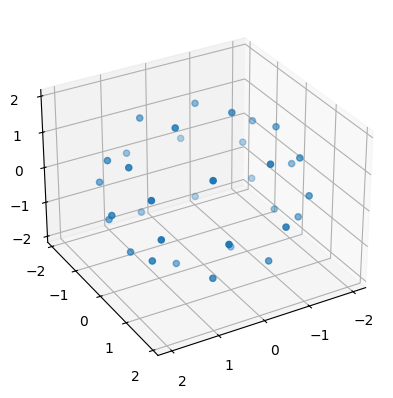

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipynb.fs.full.Task2_Detector import Detector
from ipynb.fs.full.Task3_Source import Source as Source
from ipynb.fs.full.Task1_Source import Source as SourceGen
import time as pT
from functools import wraps
from collections import defaultdict

execution_times_dict = defaultdict(list)

def timer(func):
    @wraps(func)
    def wrapper(*args, **kwargs):
        start_time = pT.perf_counter() 
        result = func(*args, **kwargs)    
        end_time = pT.perf_counter()
        execution_time = end_time - start_time
        execution_times_dict[func.__name__].append(execution_time)
        print(f"[{func.__name__}] executed in {execution_time:.6f} seconds")
        return result  
    return wrapper


def points_of_photons_intersection_with_sphere(position, directions, sphere_R: float, sphere_position: np.ndarray):
    """Function to find interstion of line and sphere points"""
    r0 = position
    d = directions
    p = sphere_position
    R2 = sphere_R**2

    scalar = d @ (r0-p)
    discriminant = scalar**2 - ((r0-p) @ (r0-p) - R2)
    mask = discriminant >= 0
    if not mask.any(): return np.empty((0, 3)) 
    t = -scalar[mask] + np.sqrt(discriminant[mask]) 
    return r0 + (d[mask].T * t).T , np.linalg.norm((d[mask].T * t).T, axis=1) # points of intersection with sphere, distance from start 

def get_FWHM(hist, bins):
    """Function for getting full width at half maximum of distribution"""
    x = (bins[1:] + bins[:-1])/2
    y = hist
    i = np.argmax(y)
    yh = y[i] / 2
    def interp(j):
        return x[j] + (yh - y[j]) * (x[j+1] - x[j]) / (y[j+1] - y[j])
    kl = np.where((y[:i] - yh) * (y[1:i+1] - yh) <= 0)[0]
    kr = np.where((y[i:-1] - yh) * (y[i+1:] - yh) <= 0)[0]
    xl = interp(kl[-1])       if kl.size else np.nan
    xr = interp(i + kr[0])    if kr.size else np.nan
    return xr - xl, xl, xr

#### Запуск N_events событий с $E = 1\, МэВ$ двумя вариантами источника

In [2]:
@timer
def generate_only_numpy(N_events=1):
    det = Detector(N=40, position=(0.,0.,0.))
    total_charge = np.empty(N_events, dtype=np.float64)
    for e in range(N_events):
        source = Source(energy=1, position=(0.,0.,0.))
        intersection_points, traveled_paths = points_of_photons_intersection_with_sphere(source.position, source.directions, det.R, det.position)
        hits_photons = det.points_are_in_pm(intersection_points, traveled_paths) # [om_id, weighted n photons in it]
        hits_phe = det.make_charge(hits_photons) # [om_id, phe]
        total_charge[e] = hits_phe[:, 1].sum()
    
    return total_charge

@timer
def generate_with_source_generator(N_events=1):
    det = Detector(N=40, position=(0.,0.,0.))
    total_charge = np.zeros(N_events, dtype=np.float64)
    for e in range(N_events):
        source = SourceGen(energy=1, position=(0.,0.,0.))
        for photons_dir in source.generator:    
            intersection_points, traveled_paths = points_of_photons_intersection_with_sphere(source.position, photons_dir, det.R, det.position)
            hits_photons = det.points_are_in_pm(intersection_points, traveled_paths) # [om_id, weighted n photons in it]
            hits_phe = det.make_charge(hits_photons) # [om_id, phe]
            total_charge[e] += hits_phe[:, 1].sum()
        
    return total_charge

[generate_only_numpy] executed in 1.614084 seconds
[generate_with_source_generator] executed in 2.411791 seconds
[generate_only_numpy] executed in 8.229255 seconds
[generate_with_source_generator] executed in 10.668991 seconds
[generate_only_numpy] executed in 15.779303 seconds
[generate_with_source_generator] executed in 20.996677 seconds


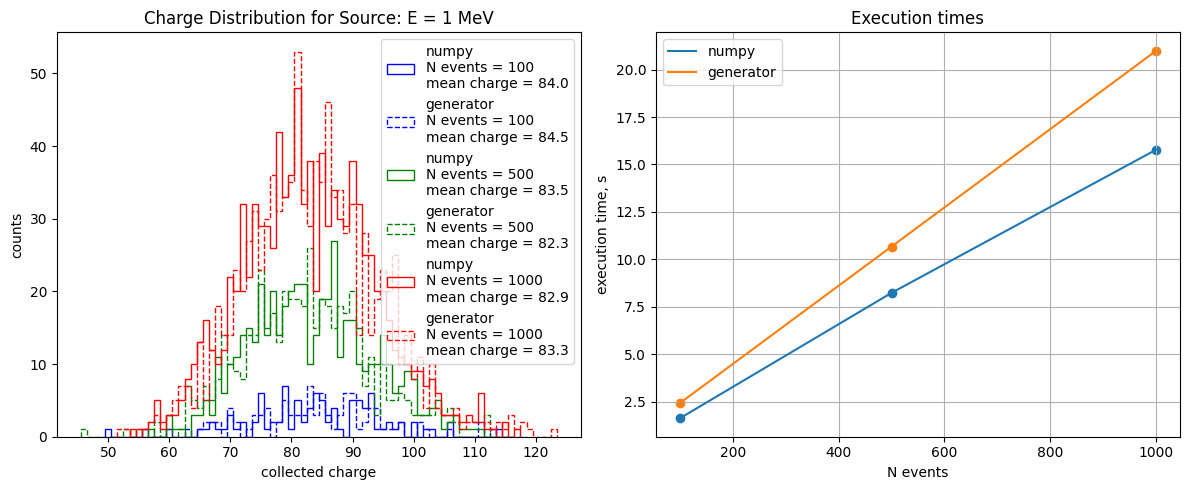

In [4]:
execution_times_dict = defaultdict(list) # renew dict
from matplotlib.colors import BASE_COLORS
base_colours = tuple(BASE_COLORS.values())

N_events_tuple = (100, 500, 1000)
funcs = [generate_only_numpy, generate_with_source_generator]
linestyles = ('-', '--')
label = ("numpy", "generator")

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
ax = axs[0]
for i, N in enumerate(N_events_tuple):
    for f, func in enumerate(funcs):
        total_charge = func(N)
        mean_charge = total_charge.mean()
        ax.hist(total_charge, bins=np.arange(total_charge.min()-0.5, total_charge.max()+0.5, 1), histtype='step', color=base_colours[i], ls=linestyles[f], label=f"{label[f]}\nN events = {N}\nmean charge = {mean_charge:.1f}")
        ax.set_title(f"Charge Distribution for Source: E = 1 MeV")
        ax.set_ylabel("counts")
        ax.set_xlabel("collected charge")
        ax.grid()
        ax.legend()

ax = axs[1]
for f, func in enumerate(funcs):
    ax.plot(N_events_tuple, execution_times_dict[func.__name__], label=f"{label[f]}")
    ax.scatter(N_events_tuple, execution_times_dict[func.__name__])
ax.set_xlabel("N events")
ax.set_ylabel("execution time, s")
ax.set_title("Execution times")
ax.grid()
ax.legend()

plt.tight_layout()
